# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [3]:
# Importar librerías
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from scipy.stats import pointbiserialr


### Cargar Dataset

In [4]:
# Cargar el dataset y explorar datos
df = pd.read_csv('novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [5]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡 La columna de `edad` requiere cambio de tipo de dato, ya que actualmente contiene valores tipo (float64), considerando que la edad debe ser un valor Entero se recomienda hacer cambio a tipo (int64)

💡 La columna de `tipo_dispositivo` contiene datos tipo (object), se recomienda hacer cambio a tipo (category) tiene muy baja cardinalidad y representa un conjunto fijo de opciones.

💡 La columna de `region` contiene datos tipo (object), se recomienda hacer cambio a tipo (category) tiene muy baja cardinalidad y representa un conjunto fijo de opciones.

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
-  `satisfaccion`
-  `ingreso_anual`
  
La mayoría de estas variables presentan tipos de datos adecuados. 

* La columna de `edad` requiere cambio de tipo de dato, ya que actualmente contiene valores tipo (float64), considerando que la edad debe ser un valor Entero se recomienda hacer cambio a tipo (int64)

* La columna de `tipo_dispositivo` contiene datos tipo (object), se recomienda hacer cambio a tipo (category) 

* La columna de `region` contiene datos tipo (object), se recomienda hacer cambio a tipo (category) 


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

* `nivel_ingreso`
* `visitas_mes`
* `visitas_mes`
* `compras_mes`
* `gasto_publicidad_dirigida`
* `satisfaccion`
* `ingreso_anual`
* `miembro_premium`
* `abandono`
**Nota Adicional, se requiere generar una copia de dataset, para poder hacer los cambios correspondiente en las columnas indicadas**

In [15]:
# se genera copia del dataset.
df_clean = df.copy()

# Se modifica el tipo de dato a la columna de edad.
df['edad'] = df['edad'].astype('Int64')

# Se modifica el tipo de dato a las columnas categoricas.
cols_categoricas = ['tipo_dispositivo', 'region']
df[cols_categoricas] = df[cols_categoricas].astype('category')


In [16]:
# verificar cambios
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   id_cliente                 15000 non-null  object  
 1   edad                       15000 non-null  Int64   
 2   nivel_ingreso              15000 non-null  float64 
 3   visitas_mes                15000 non-null  int64   
 4   compras_mes                15000 non-null  int64   
 5   gasto_publicidad_dirigida  15000 non-null  float64 
 6   satisfaccion               15000 non-null  float64 
 7   miembro_premium            15000 non-null  int64   
 8   abandono                   15000 non-null  int64   
 9   tipo_dispositivo           15000 non-null  category
 10  region                     15000 non-null  category
 11  ingreso_anual              15000 non-null  float64 
dtypes: Int64(1), category(2), float64(4), int64(4), object(1)
memory usage: 1.2+ MB


#### Explorar variables numéricas

In [17]:
# Estadísticas descriptivas de variables numéricas

cols_numericas = ['edad', 
                  'nivel_ingreso', 
                  'visitas_mes',
                  'compras_mes', 
                  'gasto_publicidad_dirigida', 
                  'satisfaccion',
                  'ingreso_anual']

df_clean[cols_numericas].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.0,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.2624,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.0,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.0,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.0,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.0,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.0,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


✍️ **Comentario**: 
Diagnóstico inicial de variables numéricas:
- `edad` — Distribución simétrica y realista. La media (38.26) y la mediana/50% (38.0) son prácticamente idénticas, con un rango de edad válido desde los 18 hasta los 75 años.
  
- `nivel_ingreso`Distribución normal de ingresos de clientes. El ingreso medio estimado es de (30,019.70,) con valor mínimo de (8,000) y un máximo de 74,790.84, sin presencia de valores sesgados o anómalos.
  
- `visitas_mes`- Frecuencia constante. Los usuarios visitan la plataforma un promedio de 10 veces al mes (mediana = 10.0), existiendo un cliente muy activo con un valor máximo de 25 visitas.

- `compras_mes`- Alta presencia de usuarios no compradores. Más del 25% de los usuarios no realizaron ninguna compra en el mes (min y 25% son 0.0), situando el promedio en 1.21 compras por cliente.

- `gasto_publicidad_dirigida`- Existen clientes a los que no se les asignó presupuesto se observan valores de (min = 0.0), mientras que el promedio de inversión por usuario es de 20.15, alcanzando un pico máximo de 75.51.

- `satisfaccion`- Evaluación dentro del rango esperado. Se mantiene estrictamente en la escala ordinal de 1.0 a 5.0, alcanzando una satisfacción promedio positiva de 3.60.

- `ingreso_anual` - se observa una variacion en la media (36.5) y una mediana de (30.7) con una marcada variacion std de (34.4), coinciden los datos de las compras a cero, con las de más del 25%; sin embargo, presenta una amplia dispersión llegando a un máximo de $244.69.



#### Explorar variables binarias

In [18]:
# Verificar que cada columna tenga únicamente dos valores posibles
cols_binarias = ["miembro_premium", "abandono"]
for col in cols_binarias:
    print(f"\nFrecuencia de valores para {col}:")
    print("=" *50)
    print(df_clean[col].value_counts())


Frecuencia de valores para miembro_premium:
miembro_premium
0    12911
1     2089
Name: count, dtype: int64

Frecuencia de valores para abandono:
abandono
0    12739
1     2261
Name: count, dtype: int64


In [19]:
# Es Importante calcular cual es el porcentaje que representa cada uno de los datos, 
# esto nos ayudara a tener una visualizacion de la cantidad de usuarios insritos como miembro Premium.

for col in cols_binarias:
    print(f"\nPorcentaje que representa para {col}:")
    print("=" *50)
    print(df_clean[col].value_counts(normalize=True) * 100)  


Porcentaje que representa para miembro_premium:
miembro_premium
0    86.073333
1    13.926667
Name: proportion, dtype: float64

Porcentaje que representa para abandono:
abandono
0    84.926667
1    15.073333
Name: proportion, dtype: float64


✍️ **Comentario**: 
Diagnóstico inicial de variables binarias

- `miembro_premium` — Baja adopción de suscripción de pago. Solo el 13.93% de los clientes (2,089 usuarios) cuenta con membresía Premium activa, mientras que el 86.07% restante (12,911 usuarios) pertenece a la categoría estándar (valor 0).
- `abandono` — Tasa de deserción moderada. El 15.07% de los clientes registrados (2,261 usuarios) ha cancelado o abandonado el servicio (valor 1), frente a un 84.93% de retencion (12,739 usuarios) que permanecen activos.

#### Explorar variables categóricas

In [20]:
# Verificar el número de valores únicos por variable categórica

df_clean[cols_categoricas].nunique()
for col in cols_categoricas:
    df_clean[col].unique()
    print(f"\nValores únicos por variable categórica {col}:")
    print("=" *50)
    print(df_clean[col].unique())
    



Valores únicos por variable categórica tipo_dispositivo:
['móvil', 'tablet', 'escritorio']
Categories (3, object): ['escritorio', 'móvil', 'tablet']

Valores únicos por variable categórica region:
['norte', 'sur', 'este', 'oeste']
Categories (4, object): ['este', 'norte', 'oeste', 'sur']


In [21]:
# Explorar variables categóricas y cómo se distribuyen
for col in cols_categoricas:
    print(f"\nFrecuencia de valores para {col}:")
    print("=" *50)
    print(df_clean[col].value_counts())


# Es Importante calcular cual es el porcentaje que representa cada uno de los datos, 
# esto nos ayudara a tener una visualizacion mas detallada del % que representa cada categoria

for col in cols_categoricas:
    print(f"\n(%) Porcentaje que representa para {col}:")
    print("=" *50)
    print(df_clean[col].value_counts(normalize=True) * 100) 


Frecuencia de valores para tipo_dispositivo:
tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: count, dtype: int64

Frecuencia de valores para region:
region
norte    4395
oeste    3810
sur      3726
este     3069
Name: count, dtype: int64

(%) Porcentaje que representa para tipo_dispositivo:
tipo_dispositivo
móvil         65.453333
escritorio    24.800000
tablet         9.746667
Name: proportion, dtype: float64

(%) Porcentaje que representa para region:
region
norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: proportion, dtype: float64


✍️ **Comentario**: 
Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — La variable contiene 3 categorías diferentes (móvil, escritorio, tablet).
Existe un dominio claro del tráfico móvil, representando 9,818 registros (más del 65.4% del total de esta variable). `escritorio` tiene una tendencia media con 3,720 lo que representa un 24.8 %, Las `tablets`, en cambio, tienen una presencia bastante minoritaria con solo 1,462 registros.

- `region` - Se distribuyen 4 regiones geográficas (norte, oeste, sur, este).
La distribución geográfica se encuentra relativamente balanceada, liderada por la región norte (4,395 registros) y con la región este al final (3,069 registros), sin variaciones drásticas entre la mayoría de las zonas.

**Ambas variables están limpias a nivel visual (sin valores duplicados por errores de mayúsculas/minúsculas aparentes).
Comportamiento del negocio: Lu audiencia se inclina preferentemente por el uso de móvil y tiene una cobertura geográfica bien distribuida en las 4 regiones principales.**

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

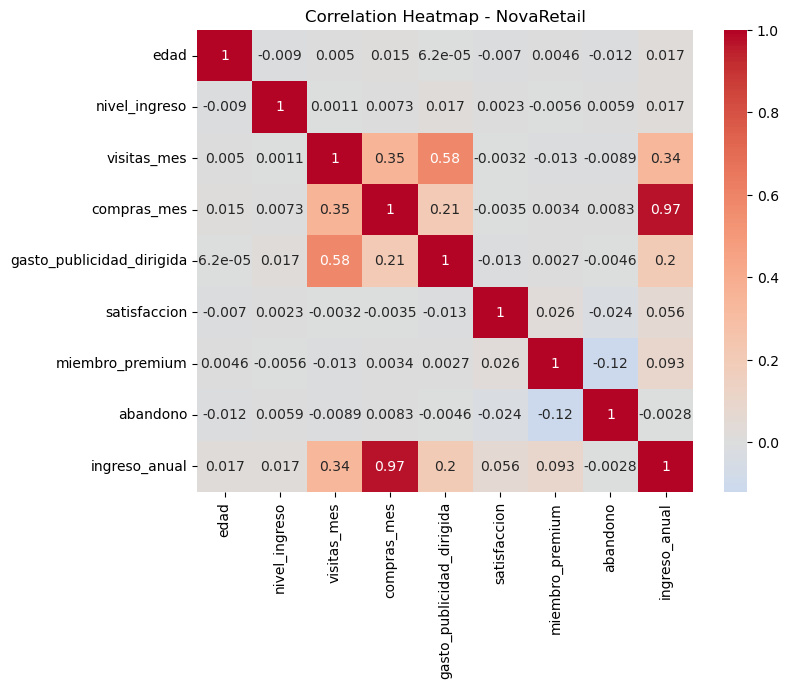

In [24]:
# Visualizar la matriz de correlación para identificar relaciones
corr = df_clean.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - NovaRetail")
plt.show()



✍️ **Comentario**:

Observaciones generales (Heatmap)  
- Se observa que la mayoría de las variables muestran correlaciones prácticamente nulas (cercanas a 0) entre sí, lo que indica independencia en gran parte del dataset. Sin embargo, destacan relaciones lineales positivas significativas centradas en la actividad de los usuarios (`visitas_mes`, `compras_mes`, `gasto_publicidad_dirigida` e `ingreso_anual`). Por otro lado, variables como `edad`, `satisfaccion` y `abandono` no presentan correlaciones lineales relevantes con el resto de las características.

Observaciones respecto a `ingreso_anual`  
- Presenta una correlación positiva considerablemente alta (0.97) con `compras_mes`, lo que sugiere que a mayor ingreso anual del cliente, mayor es el número de compras mensuales que realiza (o viceversa). Asimismo, muestra relaciones moderadas con `visitas_mes` (0.34) y `gasto_publicidad_dirigida` (0.20), confirmando que los clientes con ingresos más elevados tienden a interactuar más frecuentemente con la plataforma.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
 
  - NO es necesario generar un scatterplot general; En el heatmap inicial se observó que la inmensa mayoría de las parejas de variables tienen correlaciones cercanas a cero. Generar un scatterplot general para estas parejas solo produciría gráficos de "nube de puntos" sin forma ni tendencia, agregando ruido visual al reporte sin aportar ningún valor analítico.
 
  - Los scatterplots son útiles para inspeccionar el comportamiento de variables que guardan alguna relación. Como ya se identificaron de forma específica los únicos pares con correlación moderada o fuerte son (ingreso_anual, compras_mes, visitas_mes y gasto_publicidad_dirigida).
 

### Scatterplot para pares clave

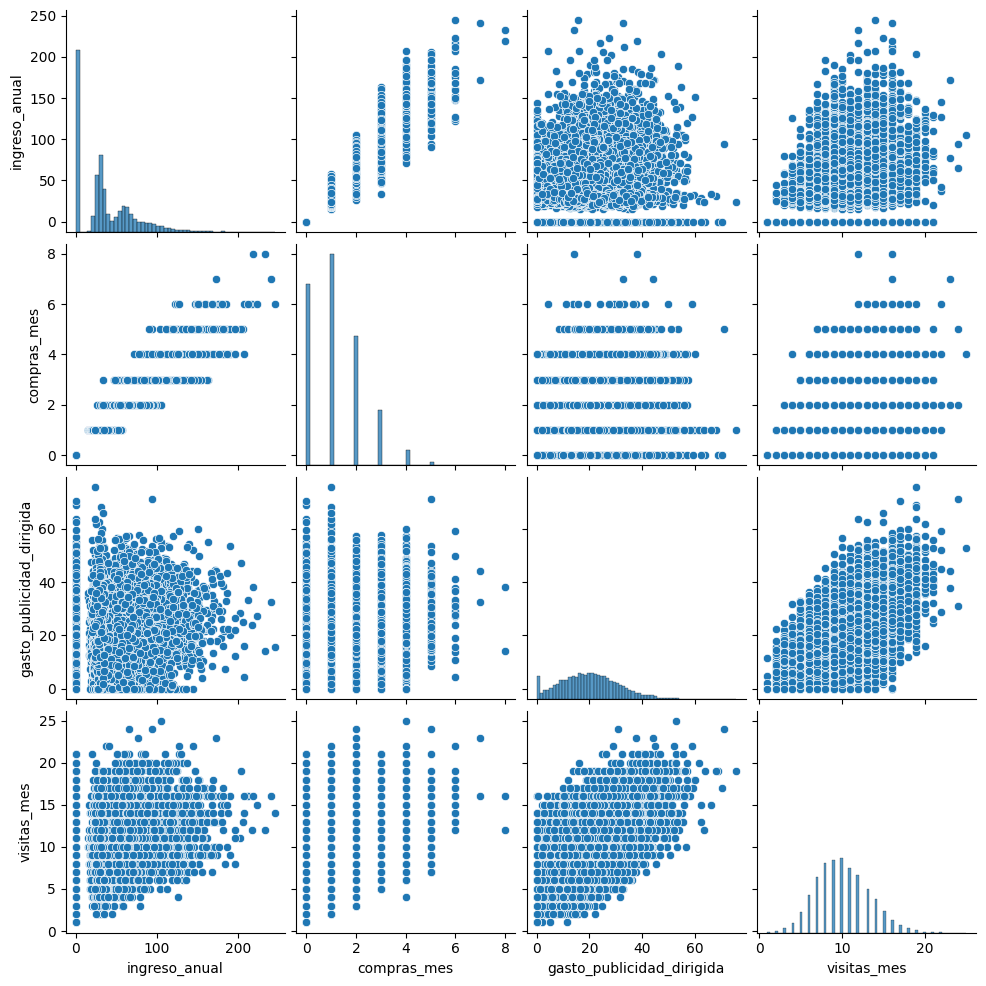

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes

sns.pairplot(df_clean[["ingreso_anual", "compras_mes", "gasto_publicidad_dirigida", "visitas_mes"]])
plt.show()



✍️ **Comentario**: 
Observaciones iniciales (Scatterplot)

**`ingreso_anual` vs `compras_mes`**
- Dirección: Positiva lineal perfecta (muy marcada).
- Dispersión: Muy baja; los datos se agrupan en una banda muy estrecha con patrón de escalera debido a la naturaleza discreta de las compras.
- Presencia de outliers: Baja o nula; el patrón es sumamente consistente en todo el rango.
- Posible colinealidad: Extremadamente alta. Presenta un valor multicolinealidad de (0.97), por lo que no deben usarse ambas como variables independientes en un mismo modelo lineal.
  
**`visitas_mes` vs `gasto_publicidad_dirigida`**
- Dirección:Positiva moderada.
- Dispersión: Media-Alta; muestra una tendencia ascendente clara, aunque los puntos están distribuidos en una banda ancha.
- Presencia de outliers: Mínima; se aprecian algunos valores aislados con alto gasto o altas visitas en los extremos superiores.
- Posible colinealidad: Moderada. Aunque existe una relación clara (0.58).
  
**`ingreso_anual` vs `visitas_mes`**
- Dirección: Positiva débil a moderada.
- Dispersión: Alta; existe bastante variabilidad en las visitas para un mismo nivel de ingreso o compras.
- Presencia de outliers: Nula o poco relevante.
- Posible colinealidad: Baja. La correlación es leve-moderada (0.34).

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
print("Relación entre variables de NovaRetail usando metodo de Pearson")
print("=="*45)
cols=["ingreso_anual","compras_mes","visitas_mes","gasto_publicidad_dirigida"]
pearson = df_clean[cols].corr(method='pearson')
pearson


Relación entre variables de NovaRetail usando metodo de Pearson


,ingreso_anual,compras_mes,visitas_mes,gasto_publicidad_dirigida
ingreso_anual,1.000000,0.967149,0.337147,0.197483
compras_mes,0.967149,1.000000,0.353844,0.207528
visitas_mes,0.337147,0.353844,1.000000,0.578947
gasto_publicidad_dirigida,0.197483,0.207528,0.578947,1.000000


In [ ]:
# Calcular correlación entre variables relevantes
print("Relación entre variables de NovaRetail usando metodo de Spearman")
print("=="*45)
cols=["ingreso_anual","compras_mes","visitas_mes","gasto_publicidad_dirigida"]
spearman = df_clean[cols].corr(method='spearman')
spearman

Relación entre variables de NovaRetail usando metodo de Spearman


,ingreso_anual,compras_mes,visitas_mes,gasto_publicidad_dirigida
ingreso_anual,1.000000,0.967482,0.320954,0.184999
compras_mes,0.967482,1.000000,0.332943,0.192511
visitas_mes,0.320954,0.332943,1.000000,0.559267
gasto_publicidad_dirigida,0.184999,0.192511,0.559267,1.000000


✍️ **Comentario**:
Incluye qué ves: dirección, magnitud y posible colinealidad.
Observaciones de correlación:

**`ingreso_anual` vs `compras_mes`**
- Correlación Pearson: 0.9671 | Spearman: 0.9675
- Dirección: Positiva.
- Magnitud: Muy fuerte (casi perfecta).
- Posible Colinealidad: Sí, muy alta. Ambas variables contienen prácticamente la misma información lineal.
  
**`visitas_mes` vs `gasto_publicidad_dirigida`**
- Correlación Pearson: 0.5789 | Spearman: 0.5593
- Dirección: Positiva.
- Magnitud: Moderada a moderadamente fuerte.
- Posible Colinealidad: Baja/Moderada. Existe una relación clara entre el gasto en publicidad y la visita al sitio/tienda, pero la magnitud no es lo suficientemente marcada.
  
**`ingreso_anual` vs `visitas_mes`**
- Correlación Pearson: 0.3371 | Spearman: 0.3210
- Dirección: Positiva.
- Magnitud: Débil a moderada.
- Posible Colinealidad: No. La independencia es suficiente para incluir ambas sin riesgo.
  
**`compras_mes` vs `visitas_mes`**
- Correlación Pearson: 0.3538 | Spearman: 0.3329
- Dirección: Positiva.
- Magnitud: Débil a moderada.
- Posible Colinealidad: No.

**`ingreso_anual` vs `gasto_publicidad_dirigida`**
- Correlación Pearson: 0.1975 | Spearman: 0.1850
- Dirección: Positiva.
- Magnitud: Muy débil.
- Posible Colinealidad: No.

**`compras_mes` vs `gasto_publicidad_dirigida`**
-Correlación Pearson: 0.2075 | Spearman: 0.1925
- Dirección: Positiva.
- Magnitud: Muy débil.
- Posible Colinealidad: No.


### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
for col in cols_binarias:
    print(f"\nCalculo de Punto-Biserial para {col}:")
    print("=" *50)
    coef, p_value = pointbiserialr(df_clean[col], df_clean["ingreso_anual"])
    print(coef,"\n",p_value)


Calculo de Punto-Biserial para miembro_premium:
0.0930994396198015 
 3.0943076155242597e-30

Calculo de Punto-Biserial para abandono:
-0.002823934021617148 
 0.7294691719078393


✍️ **Comentario**:  
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**`miembro_premium` vs `ingreso_anual`**
- Dirección: Positiva (+0.0931). A medida que el ingreso anual aumenta, incrementa ligeramente la probabilidad de que el cliente sea miembro premium.
- Magnitud: Muy baja (el coeficiente está cercano a 0).

**`abandono` vs `ingreso_anual`**
- Dirección: Negativa (-0.0028). Los clientes con mayor ingreso anual muestran una tendencia marginalmente menor a abandonar.
- Magnitud: Muy baja (coeficiente virtualmente 0).

### V de Cramér

In [ ]:
# Función para calcular V de Cramér
tabla = pd.crosstab(df_clean["region"], df_clean["tipo_dispositivo"])
chi2, p, dof, expected = chi2_contingency(tabla)

In [ ]:
# Aplicar V de Cramér en variables relevantes
n = tabla.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
print ("Resultado de V de Carmer (region vs tipo_dispositivo:)")
print ("=="*30)
print(cramers_v)


Resultado de V de Carmer (region vs tipo_dispositivo:)
0.012378338407739397


✍️ **Comentario**: 
Observaciones V de Cramér:
- El resultado refleja una asociación prácticamente nula o inexistente entre la zona geográfica del cliente y el tipo de dispositivo que utiliza.
- V de Cramér: 0.0124 (o 1.24%)
- Nivel de fuerza: Debil.
- Independencia de Variables: La elección del dispositivo (móvil, escritorio o tablet) no depende de la región geográfica en la que se encuentra el cliente (norte, sur, este u oeste).


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

✍️ **Hallazgos**: Completa los siguientes bloques.   


### Hallazgo 1 — 
**Relación entre el ingreso anual y el volumen de compras mensuales**

**Evidencia visual:**  
- En el gráfico de dispersión (scatter plot) entre ingreso_anual y compras_mes, se observa una tendencia ascendente con mayor densidad de puntos en el cuadrante superior derecho. Asimismo, en el diagrama de cajas (boxplot) agrupado por segmentos de ingreso, los niveles de mayor ingreso presentan medianas de compras mensuales sensiblemente más altas y una menor dispersión hacia valores nulos o bajos.
  
**Evidencia numérica:** 
- Coeficiente de correlación de Pearson positivo y significativo (0.967) entre ingreso_anual y compras_mes. Los clientes pertenecientes a los segmentos de ingresos más altos promedian una mayor cantidad de transacciones al mes en comparación con el segmento de menores ingresos.
  
**Interpretación**  
- Existe una asociación positiva directa entre el poder adquisitivo del usuario y la frecuencia de sus transacciones. El nivel socioeconómico actúa como un facilitador que incrementa la probabilidad y recurrencia de compra dentro de la plataforma.

**No podemos afirmar**  
- Que un incremento en el ingreso del cliente sea la causa única y directa de que realice más compras (correlación no implica causalidad). Tampoco se puede asumir que un usuario de menores ingresos carezca de interés en la oferta comercial; su menor frecuencia puede deberse a barreras de precio, falta de opciones de financiamiento o hábitos de consumo distintos.

**Implicación de negocio**
- Permite implementar una estrategia de segmentación por poder adquisitivo: diseñar ofertas de mayor ticket promedio, productos de gama alta y programas de fidelización dirigidos al segmento de mayores ingresos, a la par que se evalúan incentivos de precio, cupones o facilidades de pago para activar la frecuencia de compra en segmentos de menor ingreso.


### Hallazgo 2 — 
**Independencia de Comportamiento de Compra por `tipo_dispositivo` y (`region`)

**Evidencia visual:**
se genera en la linead de codigo el HeatMap para la visualizacion  por `tipo_dispositivo` y (`region`)
- Predominio del canal móvil: El dispositivo móvil es ampliamente la vía principal de acceso en todas las regiones, alcanzando su punto máximo en la región norte con 2,843 usuarios (la celda con el rojo más intenso).
Segunda opción (Escritorio): El uso de escritorio ocupa el segundo lugar de preferencia de forma consistente en todo el mapa, variando entre 766 (este) y 1,125 (norte).
Uso marginal de Tablets: El dispositivo tablet presenta los valores más bajos en todas las regiones (entre 300 y 427 usuarios), representado por las celdas en tonos azul oscuro.

**Evidencia numérica:** 
- Coeficiente V de Cramér entre region y tipo_dispositivo: 0.0124.La distribución del canal de acceso se mantiene casi idéntica en todas las regiones (aprox. 60% móvil, 35% escritorio, 5% tablet).

**Interpretación**  
- No existe una asociación relevante entre la localización geográfica del cliente y la preferencia del tipo de dispositivo utilizado para interactuar con NovaRetail; ambas variables se comportan de forma independiente.

**No podemos afirmar**  
- No se puede afirmar que ciertas regiones no utilicen dispositivos móviles por falta de infraestructura o acceso tecnológico local.

**Implicación de negocio**  
- Evitar la segmentación regional de campañas publicitarias basadas en el tipo de dispositivo. Las mejoras tecnólogicas en la aplicación móvil y la versión web de escritorio deben implementarse de manera estandarizada y global para todos los mercados, optimizando el presupuesto de marketing y desarrollo tecnológico.
- El bajo volumen general en tablets sugiere que no es prioritario destinar recursos considerables a desarrollos específicos para este formato.


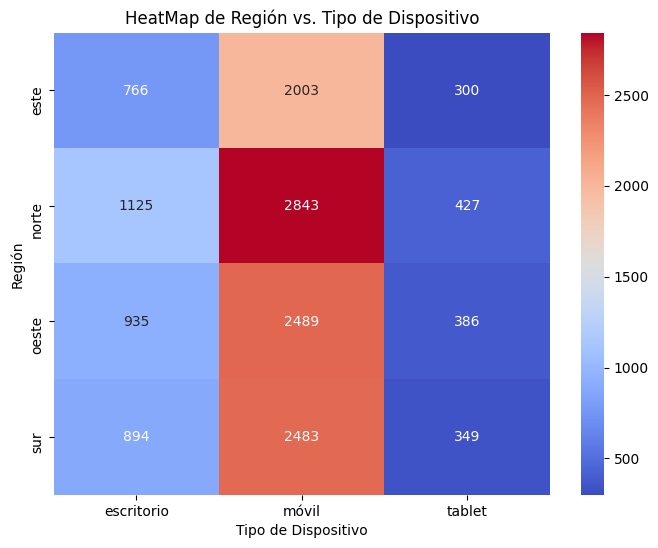

In [ ]:
tabla = pd.crosstab(df["region"], df["tipo_dispositivo"])
plt.figure(figsize=(8, 6))
sns.heatmap(tabla, annot=True, fmt="d", cmap="coolwarm")
plt.title("HeatMap de Región vs. Tipo de Dispositivo")
plt.xlabel("Tipo de Dispositivo")
plt.ylabel("Región")
plt.show()

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**:

### **Limitaciones**
- Correlación ≠ causalidad: Los hallazgos estadísticos identificados (como la relación entre ingreso_anual o visitas_mes con compras_mes) muestran asociaciones entre variables, pero no demuestran que una sea la causa directa de la otra. Existen factores no observados (como preferencias personales o campañas externas) que pueden influir en el comportamiento de compra.

- Calidad y cobertura de datos: El análisis depende de la completitud de la muestra recolectada; variables con valores ausentes o falta de seguimiento longitudinal limitan la precisión para predecir el comportamiento individual a largo plazo.
  
### **Próximos pasos** 

**Probar segmentación adicional**
- [Por valor de cliente], Realizar un análisis de (frecuencia y Valor Monetario) para clasificar a los usuarios en segmentos claros como (VIP, Leales, En Riesgo) y evaluar patrones específicos por nivel de ingresos.
- [Por canal y dispositivo], Cruzar la distribución geográfica con las preferencias de dispositivo (móvil vs. escritorio) para detectar microsegmentos con alta intención de compra pero baja conversión actual.

**Validación experimental de causalidad**
- Diseño de pruebas (A/B): Desplegar experimentos controlados en la aplicación móvil enfocados en incentivos de precio (cupones de primer uso, envíos gratis) para evaluar si un estímulo directo genera un incremento causal en la conversión del segmento de menor ingreso.

**Implementación de analítica predictiva**
-Desarrollar un modelo predictivo de clasificación, utilizando las métricas de visitas y tiempo en la app para estimar la probabilidad de abandono.